# The Same Value, Different Bytes

A value has a logical meaning; memory and file formats give it a physical
representation. Those layers are easy to conflate, especially when a native
structure appears to work as a file format on one machine.

**Research question.** Which parts of an integer record's byte representation
are defined by an explicit format, which parts depend on a C implementation,
and what evidence is sufficient to reconstruct earlier states after bounded
memory mutations?

**Hypothesis.** A versioned field-by-field encoding and a complete ordered event
history permit exact reconstruction for this bounded experiment. Native object
bytes alone are not a portable encoding, and missing history creates intervals
that cannot be recovered unless a later trusted checkpoint restores state.

The C engine is compiled as C17. The language rules are grounded in the WG14
C draft and C17 status material [S066, S067]; compiler modes are qualified by
GCC and Microsoft documentation [S068, S069]. Python's `struct` module supplies
an independently implemented byte-order oracle [S070]. The data are synthetic.

**Not established here.** This is not a memory-forensics technique. Freed or
overwritten memory is never read. Historical states exist only because the lab
records explicit evidence before each controlled change.

In [1]:
import hashlib
import json
import platform
import subprocess
import sys
from pathlib import Path

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display

from mydatalabnotes.representation import (
    corrupt_after_byte,
    decode_packet,
    encode_packet,
    native_executable,
    native_layout,
    native_packet,
    native_trace,
    omit_events,
    reconstruct_forward,
    reconstruct_reverse,
)

In [3]:
ROOT = Path.cwd()
get_ipython().run_line_magic("matplotlib", "inline")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_colwidth", 80)

PACKET = {"record_id": 0x01020304, "measurement_milli": -2,
          "sample_count": 0x1122, "flags": 0xA5,
          "payload": bytes.fromhex("deadbeef")}
CAPACITY, CHECKPOINT_INTERVAL, ALLOCATION_ID = 16, 3, 7
OPERATIONS = ["write:0:01020304", "modify:1:aabb",
              "copy:0:4:8", "snapshot", "release"]
OMIT_SEQUENCES, CORRUPT_SEQUENCE = {2}, 2

In [4]:
try:
    executable = native_executable(ROOT)
except FileNotFoundError:
    subprocess.run(
        [sys.executable, "tools/build_native.py"],
        cwd=ROOT, check=True, shell=False,
    )
    executable = native_executable(ROOT)
layout = native_layout(ROOT)
pd.Series({
    "python": platform.python_version(),
    "platform": f"{platform.system()} {platform.machine()}",
    "C compiler": layout["compiler"],
    "C standard macro": layout["stdc_version"],
    "C byte order": layout["byte_order"],
}, name="recorded environment").to_frame()

,recorded environment
python,3.12.13
platform,Windows AMD64
C compiler,MSVC 1944
C standard macro,201710
C byte order,little


The compiler record belongs to this execution. `__STDC_VERSION__ == 201710L`
confirms the selected C17 language mode, but identical language modes do not
imply identical structure layout, byte order, compiler behavior, or pointer
values across systems.

## 1. Representation begins with a contract

C exposes an object's bytes through character types, but integer widths,
signed representations, alignment requirements, padding, and structure layout
are properties of the implementation and declared types [S066]. Our experiment
therefore separates three layers.

In [5]:
layers = pd.DataFrame([
    ("Logical value", "record id 16909060", "mathematical/application contract"),
    ("Native object", "bytes of a C object", "compiler, ABI, host byte order"),
    ("Portable packet", "versioned big-endian fields", "this notebook's schema"),
    ("History evidence", "ordered before/after bytes", "memory-event schema"),
], columns=["layer", "example", "authority"])
layers

,layer,example,authority
0,Logical value,record id 16909060,mathematical/application contract
1,Native object,bytes of a C object,"compiler, ABI, host byte order"
2,Portable packet,versioned big-endian fields,this notebook's schema
3,History evidence,ordered before/after bytes,memory-event schema


In [6]:
integer_rows = []
for dtype in [np.int8, np.uint8, np.int16, np.uint16, np.int32, np.uint32]:
    info = np.iinfo(dtype)
    integer_rows.append({"type": dtype.__name__, "bits": info.bits,
                         "minimum": info.min, "maximum": info.max})
pd.DataFrame(integer_rows)

,type,bits,minimum,maximum
0,int8,8,-128,127
1,uint8,8,0,255
2,int16,16,-32768,32767
3,uint16,16,0,65535
4,int32,32,-2147483648,2147483647
5,uint32,32,0,4294967295


These NumPy types provide fixed widths for the Python-side experiment. In C,
`uint32_t` and friends exist only when the implementation supplies an integer
type with exactly that width. The C build and tests verify the types used here;
the packet contract still defines byte order explicitly rather than inheriting
the host's order.

## 2. One integer, two byte orders (endianness)

In [7]:
value = 0x12345678
endian_rows = [
    {"interpretation": "unsigned 32-bit", "byte order": order,
     "hex bytes": value.to_bytes(4, order).hex()}
    for order in ["big", "little"]
]
endian_rows += [
    {"interpretation": "signed 32-bit -2", "byte order": order,
     "hex bytes": (-2).to_bytes(4, order, signed=True).hex()}
    for order in ["big", "little"]
]
pd.DataFrame(endian_rows)

,interpretation,byte order,hex bytes
0,unsigned 32-bit,big,12345678
1,unsigned 32-bit,little,78563412
2,signed 32-bit -2,big,fffffffe
3,signed 32-bit -2,little,feffffff


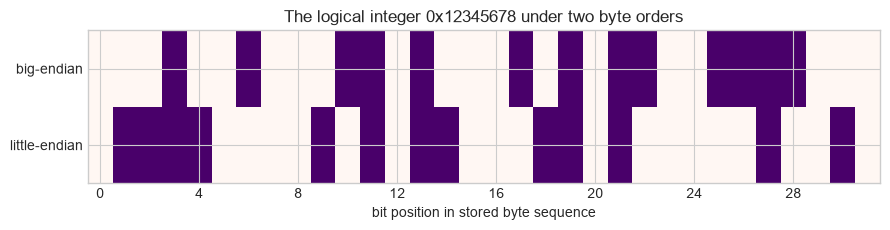

In [8]:
patterns = np.array([
    list(np.unpackbits(np.frombuffer(value.to_bytes(4, order), dtype=np.uint8)))
    for order in ["big", "little"]
])
fig, ax = plt.subplots(figsize=(9, 2.4))
ax.imshow(patterns, cmap="RdPu", vmin=0, vmax=1, aspect="auto")
ax.set(yticks=[0, 1], yticklabels=["big-endian", "little-endian"],
       xlabel="bit position in stored byte sequence")
ax.set_xticks(np.arange(0, 32, 4))
ax.set_title("The logical integer 0x12345678 under two byte orders")
fig.tight_layout(); display(fig); plt.close(fig)

The same non-negative integer round-trips under either policy when the decoder
uses the matching policy. The byte strings differ. A raw four-byte sequence has
no integer meaning until width, signedness, and byte order are supplied.

## 3. Native structure layout is an observation, not a file format

In [9]:
layout_fields = [
    ("record_id", layout["offset_record_id"], 4),
    ("measurement_milli", layout["offset_measurement_milli"], 4),
    ("sample_count", layout["offset_sample_count"], 2),
    ("flags", layout["offset_flags"], 1),
    ("payload_length", layout["offset_payload_length"], 1),
    ("payload", layout["offset_payload"], 32),
]
pd.DataFrame(layout_fields, columns=["field", "native offset", "declared bytes"])

,field,native offset,declared bytes
0,record_id,0,4
1,measurement_milli,4,4
2,sample_count,8,2
3,flags,10,1
4,payload_length,11,1
5,payload,12,32


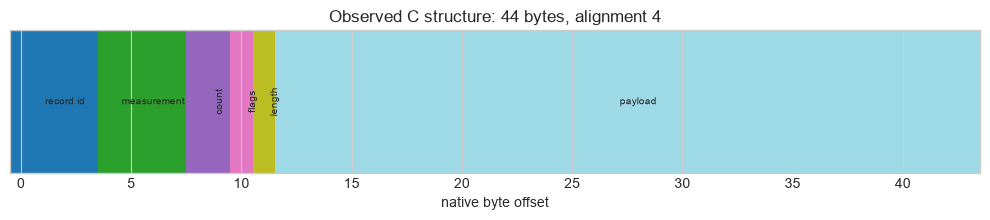

In [10]:
ownership = np.full(layout["sizeof_packet"], "padding", dtype=object)
for name, offset, width in layout_fields:
    ownership[offset:offset + width] = name
colors = {name: index for index, name in enumerate(pd.unique(ownership))}
fig, ax = plt.subplots(figsize=(10, 2.3))
ax.imshow([[colors[name] for name in ownership]], cmap="tab20", aspect="auto")
short_labels = {"record_id": "record id", "measurement_milli": "measurement",
                "sample_count": "count", "payload_length": "length"}
for name, offset, width in layout_fields:
    ax.text(offset + width / 2, 0, short_labels.get(name, name),
            ha="center", va="center", fontsize=7,
            rotation=90 if width <= 2 else 0)
ax.set(yticks=[], xlabel="native byte offset",
       title=f"Observed C structure: {layout['sizeof_packet']} bytes, alignment {layout['alignof_packet']}")
fig.tight_layout(); display(fig); plt.close(fig)

In [11]:
native_preview = [layout["native_hex"][index:index + 2]
                  for index in range(0, len(layout["native_hex"]), 2)]
pd.DataFrame({"offset": range(len(native_preview)),
              "native byte": native_preview,
              "field": ownership})

,offset,native byte,field
0,0,04,record_id
1,1,03,record_id
2,2,02,record_id
3,3,01,record_id
4,4,fe,measurement_milli
5,5,ff,measurement_milli
6,6,ff,measurement_milli
7,7,ff,measurement_milli
8,8,22,sample_count
9,9,11,sample_count


The object was zero-filled before its fields were assigned, so inspecting every
byte does not read uninitialized storage. Even so, these offsets and bytes are
only an observed host representation. Copying this structure directly to a file
would inherit its byte order, padding, total size, and compiler ABI.

## 4. Define a portable packet field by field

The synthetic packet uses magic `MDLN`, format version 1, big-endian integers,
explicit signedness, and a bounded payload of 1–32 bytes. No native structure is
copied into the packet.

In [12]:
packet_contract = pd.DataFrame([
    (0, 4, "magic", "4 ASCII bytes"), (4, 1, "version", "unsigned 8-bit"),
    (5, 1, "flags", "unsigned 8-bit"), (6, 4, "record_id", "unsigned 32-bit BE"),
    (10, 4, "measurement_milli", "signed 32-bit BE"),
    (14, 2, "sample_count", "unsigned 16-bit BE"),
    (16, 2, "payload_length", "unsigned 16-bit BE"),
    (18, "1–32", "payload", "opaque bytes"),
], columns=["offset", "width", "field", "encoding"])
packet_contract

,offset,width,field,encoding
0,0,4,magic,4 ASCII bytes
1,4,1,version,unsigned 8-bit
2,5,1,flags,unsigned 8-bit
3,6,4,record_id,unsigned 32-bit BE
4,10,4,measurement_milli,signed 32-bit BE
5,14,2,sample_count,unsigned 16-bit BE
6,16,2,payload_length,unsigned 16-bit BE
7,18,1–32,payload,opaque bytes


In [13]:
parameter_table = pd.Series({
    **{key: value for key, value in PACKET.items() if key != "payload"},
    "payload_hex": PACKET["payload"].hex(),
    "lab_capacity": CAPACITY,
    "checkpoint_interval": CHECKPOINT_INTERVAL,
    "operations": OPERATIONS,
}, name="reader-editable parameters")
parameter_table.to_frame()

,reader-editable parameters
record_id,16909060
measurement_milli,-2
sample_count,4386
flags,165
payload_hex,deadbeef
lab_capacity,16
checkpoint_interval,3
operations,"[write:0:01020304, modify:1:aabb, copy:0:4:8, snapshot, release]"


In [14]:
python_bytes = encode_packet(**PACKET)
c_packet = native_packet(ROOT, PACKET)
encoder_comparison = pd.DataFrame([
    ("Python struct oracle", python_bytes.hex(), len(python_bytes)),
    ("C17 field encoder", c_packet["portable_hex"], len(bytes.fromhex(c_packet["portable_hex"]))),
], columns=["implementation", "hex bytes", "byte count"])
encoder_comparison

,implementation,hex bytes,byte count
0,Python struct oracle,4d444c4e01a501020304fffffffe11220004deadbeef,22
1,C17 field encoder,4d444c4e01a501020304fffffffe11220004deadbeef,22


In [15]:
assert python_bytes.hex() == c_packet["portable_hex"]
decoded = decode_packet(python_bytes)
pd.DataFrame({"input": PACKET, "decoded": decoded}).map(
    lambda item: item.hex() if isinstance(item, bytes) else item
)

,input,decoded
record_id,16909060,16909060
measurement_milli,-2,-2
sample_count,4386,4386
flags,165,165
payload,deadbeef,deadbeef


In [16]:
field_for_offset = []
for offset in range(len(python_bytes)):
    match = packet_contract[
        packet_contract["offset"].apply(lambda item: isinstance(item, int))
        & (packet_contract["offset"] <= offset)
    ].iloc[-1]["field"]
    field_for_offset.append(match)
byte_table = pd.DataFrame({"offset": range(len(python_bytes)),
                           "hex": [f"{byte:02x}" for byte in python_bytes],
                           "field": field_for_offset})
byte_table

,offset,hex,field
0,0,4d,magic
1,1,44,magic
2,2,4c,magic
3,3,4e,magic
4,4,01,version
5,5,a5,flags
6,6,01,record_id
7,7,02,record_id
8,8,03,record_id
9,9,04,record_id


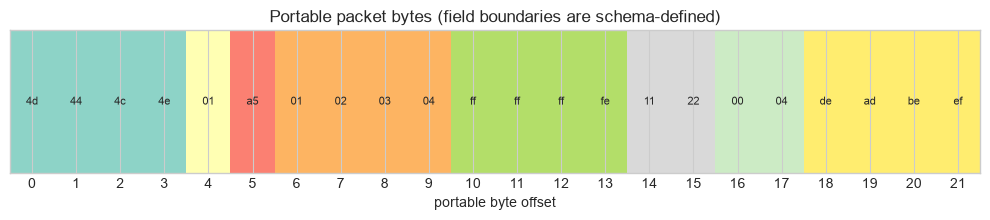

In [17]:
field_names = list(dict.fromkeys(field_for_offset))
field_codes = [field_names.index(name) for name in field_for_offset]
fig, ax = plt.subplots(figsize=(10, 2.3))
ax.imshow([field_codes], cmap="Set3", aspect="auto")
for offset, byte in enumerate(python_bytes):
    ax.text(offset, 0, f"{byte:02x}", ha="center", va="center", fontsize=8)
ax.set(yticks=[], xticks=range(len(python_bytes)), xlabel="portable byte offset",
       title="Portable packet bytes (field boundaries are schema-defined)")
fig.tight_layout(); display(fig); plt.close(fig)

The independently structured Python and C encoders produce the same bytes, and
decoding restores every declared value. This is byte-for-byte reproducibility
for schema version 1 and these inputs. It does not make the native structure
portable or prove either compiler correct.

Changing one logical field should change only its declared region plus any
derived identity. The next sensitivity check holds every other input fixed.

In [18]:
variants = []
for name, replacement in [("record_id", PACKET["record_id"] + 1),
                          ("flags", PACKET["flags"] ^ 1),
                          ("payload", bytes.fromhex("deadbeee"))]:
    changed = {**PACKET, name: replacement}
    encoded = encode_packet(**changed)
    offsets = [i for i, pair in enumerate(zip(python_bytes, encoded, strict=True))
               if pair[0] != pair[1]]
    variants.append({"changed field": name, "changed offsets": offsets,
                     "sha256": hashlib.sha256(encoded).hexdigest()[:16]})
pd.DataFrame(variants)

,changed field,changed offsets,sha256
0,record_id,[9],38aaa6ce4c7aa06b
1,flags,[5],efd0a548a6de2ba7
2,payload,[21],821f8804ad3db4aa


The changes remain within the field regions defined by the packet schema. The
truncated digest is only a compact comparison label here; a checksum or hash is
not proof of semantic correctness or authenticity.

## 5. A bounded C memory laboratory

The lab allocates at most 256 bytes, identifies the allocation with a logical
integer, and records each operation as JSON Lines. Each event contains a sequence
number, operation, offset, relevant before/after bytes, a non-cryptographic
FNV-1a state fingerprint, an optional full checkpoint, and an instrumented
reference state. The reference state is used only to grade reconstruction; the
replay algorithm does not use it as input.

In [19]:
events = native_trace(ROOT, ALLOCATION_ID, CAPACITY,
                      CHECKPOINT_INTERVAL, OPERATIONS)
event_frame = pd.DataFrame(events)
event_frame[["seq", "allocation_id", "operation", "offset", "length",
             "before_hex", "after_hex", "checkpoint_hex"]]

,seq,allocation_id,operation,offset,length,before_hex,after_hex,checkpoint_hex
0,1,7,allocate,0,16,,00000000000000000000000000000000,00000000000000000000000000000000
1,2,7,write,0,4,00000000,01020304,
2,3,7,modify,1,2,0203,aabb,01aabb04000000000000000000000000
3,4,7,copy,8,4,00000000,01aabb04,
4,5,7,snapshot,0,0,,,01aabb040000000001aabb0400000000
5,6,7,release,0,16,01aabb040000000001aabb0400000000,,


In [20]:
invariants = pd.Series({
    "sequence is contiguous": event_frame["seq"].tolist() == list(range(1, len(events) + 1)),
    "one logical allocation": event_frame["allocation_id"].nunique() == 1,
    "all offsets bounded": bool(((event_frame["offset"] + event_frame["length"]) <= CAPACITY).all()),
    "release is final": events[-1]["operation"] == "release" and not events[-1]["live"],
    "raw addresses recorded": any("address" in event for event in events),
}, name="trace invariants")
invariants.to_frame()

,trace invariants
sequence is contiguous,True
one logical allocation,True
all offsets bounded,True
release is final,True
raw addresses recorded,False


In [21]:
state_matrix = np.array([
    list(bytes.fromhex(event["reference_state_hex"]).ljust(CAPACITY, b"\x00"))
    for event in events
])
changed_counts = []
for event in events:
    before, after = bytes.fromhex(event["before_hex"]), bytes.fromhex(event["after_hex"])
    width = max(len(before), len(after))
    pairs = zip(before.ljust(width, b"\x00"), after.ljust(width, b"\x00"), strict=True)
    changed_counts.append(sum(left != right for left, right in pairs))
pd.DataFrame({"seq": event_frame["seq"], "operation": event_frame["operation"],
              "changed bytes": changed_counts,
              "checkpoint": event_frame["checkpoint_hex"].str.len() > 0})

,seq,operation,changed bytes,checkpoint
0,1,allocate,0,True
1,2,write,4,False
2,3,modify,2,True
3,4,copy,4,False
4,5,snapshot,0,True
5,6,release,8,False


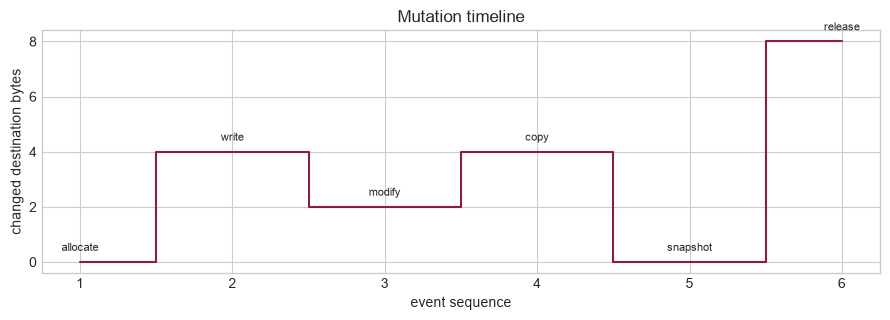

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.3))
ax.step(event_frame["seq"], changed_counts, where="mid", color="#8b1e3f")
for seq, operation in zip(event_frame["seq"], event_frame["operation"], strict=True):
    ax.annotate(operation, (seq, changed_counts[seq - 1]),
                xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)
ax.set(xlabel="event sequence", ylabel="changed destination bytes",
       xticks=event_frame["seq"], title="Mutation timeline")
fig.tight_layout(); display(fig); plt.close(fig)

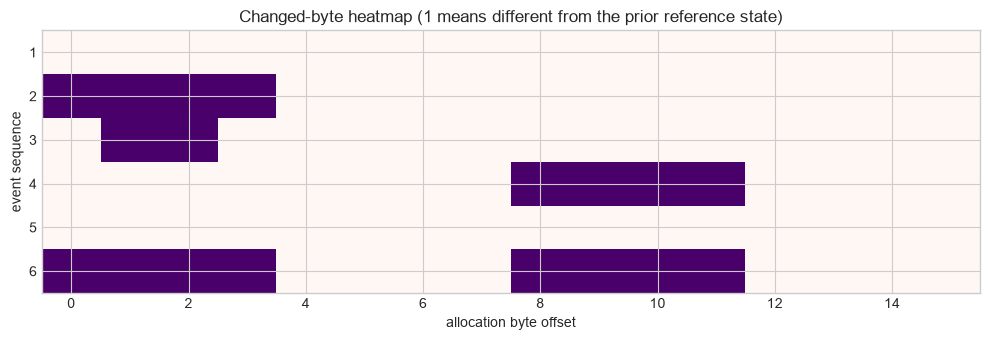

In [23]:
changes = np.zeros_like(state_matrix, dtype=int)
changes[1:] = state_matrix[1:] != state_matrix[:-1]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.imshow(changes, cmap="RdPu", vmin=0, vmax=1, aspect="auto")
ax.set(xlabel="allocation byte offset", ylabel="event sequence",
       yticks=range(len(events)), yticklabels=event_frame["seq"],
       title="Changed-byte heatmap (1 means different from the prior reference state)")
fig.tight_layout(); display(fig); plt.close(fig)

Allocation, writing, modification, overlapping-safe copying, an explicit
snapshot, and release are all visible. The release row is not a read from freed
storage: the C engine records the live bytes, clears and releases the allocation,
and then emits an event whose state is no longer live. For the heatmap only,
that absent state is drawn with zero-valued cells. This is a visualization
sentinel, not evidence that released storage remains readable or contains zeros.

## 6. Reconstruct every recorded state independently

In [24]:
forward = pd.DataFrame(reconstruct_forward(events))
forward[["seq", "operation", "status", "trusted",
         "reference_matches", "fingerprint_matches"]]

,seq,operation,status,trusted,reference_matches,fingerprint_matches
0,1,allocate,ok,True,True,True
1,2,write,ok,True,True,True
2,3,modify,ok,True,True,True
3,4,copy,ok,True,True,True
4,5,snapshot,ok,True,True,True
5,6,release,ok,True,True,True


In [25]:
forward_summary = pd.Series({
    "events reconstructed": len(forward),
    "all reference snapshots matched": bool(forward["reference_matches"].all()),
    "all fingerprints matched": bool(forward["fingerprint_matches"].all()),
    "final state live": events[-1]["live"],
}, name="forward replay evidence")
forward_summary.to_frame()

,forward replay evidence
events reconstructed,6
all reference snapshots matched,True
all fingerprints matched,True
final state live,False


In [26]:
reverse = pd.DataFrame(reconstruct_reverse(events))
reverse[["seq", "operation", "status", "reference_matches"]]

,seq,operation,status,reference_matches
0,6,release,ok,True
1,5,snapshot,ok,True
2,4,copy,ok,True
3,3,modify,ok,True
4,2,write,ok,True
5,1,allocate,ok,True


Forward replay uses the allocation snapshot and each event's before/after bytes.
Reverse replay starts after release, restores the release's recorded `before`
image, and undoes mutations in reverse order. Every reconstructed state agrees
with the C engine's independent reference snapshot. This result depends on a
complete event history and the exact declared semantics.

## 7. Checkpoint frequency changes recovery evidence, not past memory

In [27]:
checkpoint_rows = []
for interval in [0, 2, 3, 4, 6]:
    sample = native_trace(ROOT, ALLOCATION_ID, CAPACITY, interval, OPERATIONS)
    checkpoints = sum(bool(event["checkpoint_hex"]) for event in sample)
    checkpoint_rows.append({"interval": interval, "events": len(sample),
                            "checkpoints": checkpoints,
                            "checkpoint bytes": checkpoints * CAPACITY})
checkpoint_frame = pd.DataFrame(checkpoint_rows)
checkpoint_frame

,interval,events,checkpoints,checkpoint bytes
0,0,6,2,32
1,2,6,4,64
2,3,6,3,48
3,4,6,3,48
4,6,6,2,32


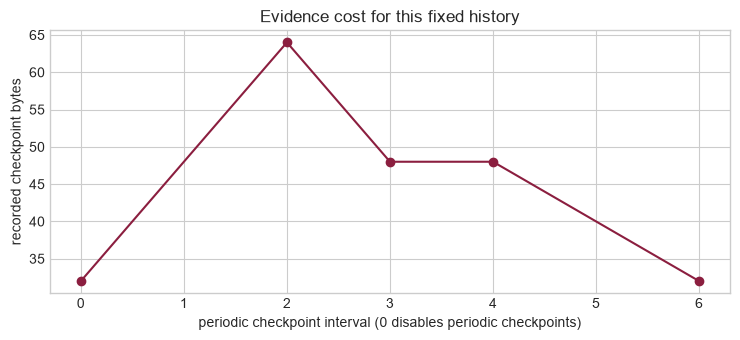

In [28]:
fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.plot(checkpoint_frame["interval"], checkpoint_frame["checkpoint bytes"], "o-",
        color="#8b1e3f")
ax.set(xlabel="periodic checkpoint interval (0 disables periodic checkpoints)",
       ylabel="recorded checkpoint bytes", title="Evidence cost for this fixed history")
fig.tight_layout(); display(fig); plt.close(fig)

The initial allocation and explicit snapshot are always checkpoints, so interval
zero does not mean “no evidence.” More periodic checkpoints record more bytes and
can shorten an untrusted interval after a missing event. They do not recover a
state that was never recorded.

## 8. Missing and corrupted histories

We now change one evidence condition at a time. `OMIT_SEQUENCES` and
`CORRUPT_SEQUENCE` are reader-editable parameters. The corrupted event flips one
recorded `after` byte but leaves its fingerprint and reference snapshot intact.
Expected failures are captured as diagnostic rows, not notebook exceptions.

In [29]:
no_periodic = native_trace(ROOT, ALLOCATION_ID, CAPACITY, 0, OPERATIONS)
scenarios = {
    "complete": events,
    "omitted with later checkpoint": omit_events(events, OMIT_SEQUENCES),
    "omitted without periodic checkpoint": omit_events(no_periodic, OMIT_SEQUENCES),
    "corrupted after byte": corrupt_after_byte(events, CORRUPT_SEQUENCE),
}
scenario_rows = []
scenario_details = {}
for name, history in scenarios.items():
    diagnosis = pd.DataFrame(reconstruct_forward(history))
    scenario_details[name] = diagnosis
    scenario_rows.append({
        "scenario": name, "recorded events": len(history),
        "detected problem rows": int((diagnosis["status"] != "ok").sum()),
        "checkpoint recoveries": int((diagnosis["status"] == "checkpoint-recovered").sum()),
        "reference matches": int(diagnosis["reference_matches"].sum()),
    })
scenario_frame = pd.DataFrame(scenario_rows)
scenario_frame

,scenario,recorded events,detected problem rows,checkpoint recoveries,reference matches
0,complete,6,0,0,6
1,omitted with later checkpoint,5,1,1,5
2,omitted without periodic checkpoint,5,3,1,3
3,corrupted after byte,6,2,1,5


In [30]:
pd.concat([
    frame.assign(scenario=name)[["scenario", "seq", "operation", "status", "notes"]]
    for name, frame in scenario_details.items()
    if name != "complete"
], ignore_index=True)

,scenario,seq,operation,status,notes
0,omitted with later checkpoint,1,allocate,ok,
1,omitted with later checkpoint,3,modify,checkpoint-recovered,sequence gap: expected 2; before bytes do not match current state; state res...
2,omitted with later checkpoint,4,copy,ok,
3,omitted with later checkpoint,5,snapshot,ok,
4,omitted with later checkpoint,6,release,ok,
5,omitted without periodic checkpoint,1,allocate,ok,
6,omitted without periodic checkpoint,3,modify,unverified,sequence gap: expected 2; before bytes do not match current state
7,omitted without periodic checkpoint,4,copy,unverified,
8,omitted without periodic checkpoint,5,snapshot,checkpoint-recovered,state restored from recorded checkpoint
9,omitted without periodic checkpoint,6,release,ok,


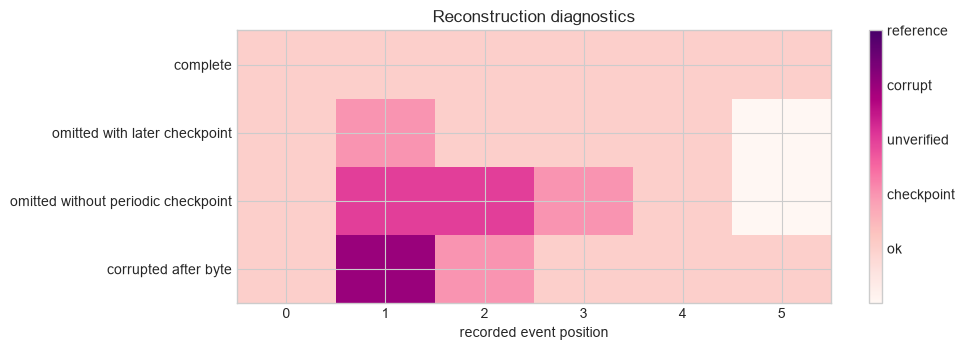

In [31]:
status_names = ["ok", "checkpoint-recovered", "unverified", "corruption-detected",
                "reference-mismatch"]
status_codes = {name: index for index, name in enumerate(status_names)}
diagnostic_matrix = np.full((len(scenarios), max(map(len, scenario_details.values()))), -1)
for row, frame in enumerate(scenario_details.values()):
    diagnostic_matrix[row, :len(frame)] = [status_codes.get(value, 4) for value in frame["status"]]
fig, ax = plt.subplots(figsize=(10, 3.6))
image = ax.imshow(diagnostic_matrix, cmap="RdPu", vmin=-1, vmax=len(status_names)-1, aspect="auto")
ax.set(yticks=range(len(scenarios)), yticklabels=scenarios.keys(),
       xlabel="recorded event position", title="Reconstruction diagnostics")
colorbar = fig.colorbar(image, ax=ax, ticks=range(len(status_names)))
colorbar.ax.set_yticklabels(["ok", "checkpoint", "unverified",
                             "corrupt", "reference"])
fig.tight_layout(); display(fig); plt.close(fig)

In [32]:
information_ledger = pd.DataFrame([
    ("Complete history", "Every state", "Forward and reverse replay agree"),
    ("Missing event before checkpoint", "States after checkpoint", "Gap interval is not trusted"),
    ("Missing event without later checkpoint", "Initial and separately recorded states", "Intermediate bytes are lost"),
    ("Corrupted event", "Later trusted checkpoint states", "Fingerprint/reference detect divergence"),
    ("Released allocation without trace", "None", "Ordinary memory supplies no historical API"),
], columns=["evidence condition", "reconstructible", "limitation"])
information_ledger

,evidence condition,reconstructible,limitation
0,Complete history,Every state,Forward and reverse replay agree
1,Missing event before checkpoint,States after checkpoint,Gap interval is not trusted
2,Missing event without later checkpoint,Initial and separately recorded states,Intermediate bytes are lost
3,Corrupted event,Later trusted checkpoint states,Fingerprint/reference detect divergence
4,Released allocation without trace,None,Ordinary memory supplies no historical API


Sequence gaps, mismatching before bytes, and fingerprints expose the incomplete
or corrupted histories. A later checkpoint can re-establish the current state,
but it cannot fill the missing historical interval. Without a later checkpoint,
replay remains untrusted even when a final release event proves that no live
allocation remains. That final lifecycle fact is not a reconstruction of the
missing bytes.

## 9. Boundary behavior is part of the experiment

In [33]:
rejected = subprocess.run(
    [str(executable), "trace", "1", "8", "2", "write:8:ff"],
    cwd=ROOT, text=True, capture_output=True, shell=False, timeout=15,
)
pd.Series({"return code": rejected.returncode,
           "diagnostic": rejected.stderr.strip(),
           "events emitted": len(rejected.stdout.splitlines())},
          name="out-of-bounds operation")

return code                          3
diagnostic        operation 1 rejected
events emitted                       2
Name: out-of-bounds operation, dtype: object

The invalid write starts at the first byte beyond an eight-byte allocation. It
is rejected, the allocation is released in a controlled path, and no
out-of-bounds access is attempted. Native unit tests also cover truncated packet
input, wrong magic, duplicate release, and invalid copy ranges.

## 10. Evidence ledger and reproducibility manifest

In [34]:
evidence_ledger = pd.DataFrame([
    ("Known packet vector", "C and Python bytes agree", "Other schemas"),
    ("Host layout observation", "This compiler/ABI layout", "Cross-platform identity"),
    ("Native unit tests", "Declared boundaries and round trips", "Compiler correctness"),
    ("Complete replay", "Every recorded state reconstructed", "Unrecorded history"),
    ("Omission experiment", "Gaps detected and checkpoints recover", "Missing interval bytes"),
    ("Corruption experiment", "Divergence detected", "Cryptographic authenticity"),
], columns=["evidence", "what it establishes", "what it does not establish"])
evidence_ledger

,evidence,what it establishes,what it does not establish
0,Known packet vector,C and Python bytes agree,Other schemas
1,Host layout observation,This compiler/ABI layout,Cross-platform identity
2,Native unit tests,Declared boundaries and round trips,Compiler correctness
3,Complete replay,Every recorded state reconstructed,Unrecorded history
4,Omission experiment,Gaps detected and checkpoints recover,Missing interval bytes
5,Corruption experiment,Divergence detected,Cryptographic authenticity


In [35]:
manifest = pd.Series({
    "notebook": "The Same Value, Different Bytes",
    "schema": "mydatalabnotes.experiment.v1",
    "profile": "quick",
    "portable packet schema": "mydatalabnotes.packet.v1",
    "trace schema": "mydatalabnotes.memory-event.v1",
    "packet sha256": hashlib.sha256(python_bytes).hexdigest(),
    "trace sha256": hashlib.sha256(
        "\n".join(json.dumps(event, sort_keys=True) for event in events).encode()
    ).hexdigest(),
    "state fingerprint": "FNV-1a 64-bit; error detection only",
    "limits": f"payload <= 32 bytes; allocation <= 256 bytes; active {CAPACITY} bytes",
    "subprocess policy": "checked-in executable; argument list; shell disabled",
}, name="experiment manifest")
manifest.to_frame()

,experiment manifest
notebook,"The Same Value, Different Bytes"
schema,mydatalabnotes.experiment.v1
profile,quick
portable packet schema,mydatalabnotes.packet.v1
trace schema,mydatalabnotes.memory-event.v1
packet sha256,57dca3cb3e9da40298d80a595aa583369c4e9ca282b572737a953fde4fa6627d
trace sha256,235e7a29e8660e5aa5c9ad9bba3bc4b3a9480f773b88cea1885dcdfa999d0fc4
state fingerprint,FNV-1a 64-bit; error detection only
limits,payload <= 32 bytes; allocation <= 256 bytes; active 16 bytes
subprocess policy,checked-in executable; argument list; shell disabled


## Synthesis: what the experiments establish — and what they do not establish

The portable packet has one byte representation for each accepted version-1
value under its declared contract. The C17 encoder and independent Python
encoder agree on the known vector and the reader-editable example. By contrast,
the native structure exposes host byte order, compiler-selected alignment, and
layout. Its bytes are useful observations, not a portable storage contract.

For the complete bounded history, independent forward and reverse reconstruction
matches every instrumented C snapshot. Controlled omissions and corruption are
detected. A later trusted checkpoint restores subsequent state, but the omitted
interval remains **irretrievably lost** from the admitted evidence. The experiment
therefore supports the hypothesis under these bounds.

It does **not** establish that ordinary memory preserves an accessible history,
that released storage may be inspected, that FNV-1a supplies authentication, or
that native layouts are deterministic across compilers. It also does not model
concurrent mutation, process crashes, hardware faults, compiler defects, or an
unbounded event store. The next useful representation experiment would repeat the
known vectors on another ABI and compare only the portable bytes, while treating
native layout differences as expected observations.